Measure criterion recovery, retention and synthesis gains from individual panel responses.


In [1]:
import os, sys, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 220)
arms = P.load_main_arms()
AXES = ['accuracy', 'completeness', 'urgency', 'uncertainty', 'reasoning', 'communication_quality']


In [2]:
def axis_contrib(d):
    it = P.items(d)
    mx = it[it.points > 0].groupby('Vignette').points.sum()
    it['signed'] = np.where(it.points > 0, it.points * it.met, -np.abs(it.points) * it.met)
    g = it.groupby(['Vignette', 'axis']).signed.sum().unstack(fill_value=0)
    return g.div(mx, axis=0).reindex(columns=AXES, fill_value=0)

def decompose(a, b):
    A, B = (axis_contrib(arms[a]), axis_contrib(arms[b]))
    ix = A.index.intersection(B.index)
    diff = (A.loc[ix] - B.loc[ix]).mean()
    tot = diff.sum()
    return (pd.DataFrame({'contribution': diff, 'share': diff / tot}), tot)
rows = []
for b in ['gpt', 'deepseekv4', 'qwen']:
    dec, tot = decompose('P-base', b)
    check = P.paired(P.score(arms, 'P-base'), P.score(arms, b))['delta']
    print(f'P-base − {P.MODEL_NAME[b]}: sum of axis contributions {tot:.4f} vs mean difference {check:.4f}')
    dec['vs'] = P.MODEL_NAME[b]
    rows.append(dec.reset_index())
axis_dec = pd.concat(rows)
display(axis_dec.round(4))
P.save_table(axis_dec, 'criterion_recovery_by_scoring_axis.csv', index=False)


P-base − gpt-oss-120b: sum of axis contributions 0.1641 vs mean difference 0.1641
P-base − deepseek-v4-flash: sum of axis contributions 0.1492 vs mean difference 0.1492
P-base − qwen3-235b-a22b: sum of axis contributions 0.2277 vs mean difference 0.2277


,axis,contribution,share,vs
0,accuracy,0.0161,0.0978,gpt-oss-120b
1,completeness,0.0677,0.4122,gpt-oss-120b
2,urgency,0.0204,0.1240,gpt-oss-120b
3,uncertainty,0.0309,0.1881,gpt-oss-120b
4,reasoning,0.0159,0.0969,gpt-oss-120b
5,communication_quality,0.0133,0.0810,gpt-oss-120b
0,accuracy,0.0142,0.0953,deepseek-v4-flash
1,completeness,0.0771,0.5168,deepseek-v4-flash
2,urgency,0.0128,0.0855,deepseek-v4-flash
3,uncertainty,0.0260,0.1744,deepseek-v4-flash


saved tables/criterion_recovery_by_scoring_axis.csv (18 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\criterion_recovery_by_scoring_axis.csv'

In [3]:
def axis_rates(d):
    it = P.items(d)
    pos = it[it.points > 0]
    earned = (pos.points * pos.met).groupby(pos.axis).sum() / pos.points.groupby(pos.axis).sum()
    pen = it[it.points < 0].groupby('axis').met.mean()
    return (earned, pen)
rates = {}
for n in ['gpt', 'qwen', 'deepseekv4', 'homog gpt', 'P-base']:
    e, p = axis_rates(arms[n])
    rates[P.MODEL_NAME.get(n, n)] = e
rates = pd.DataFrame(rates).reindex(AXES)
display(rates.round(3))
P.save_table(rates, 'criterion_success_rates_by_axis.csv')


,gpt-oss-120b,qwen3-235b-a22b,deepseek-v4-flash,homog gpt,P-base
axis,,,,,
accuracy,0.843,0.789,0.846,0.862,0.892
completeness,0.518,0.383,0.486,0.682,0.725
urgency,0.774,0.733,0.816,0.892,0.897
uncertainty,0.259,0.273,0.316,0.598,0.562
reasoning,0.774,0.772,0.810,0.886,0.905
communication_quality,0.451,0.483,0.521,0.530,0.637


saved tables/criterion_success_rates_by_axis.csv (6 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\criterion_success_rates_by_axis.csv'

In [4]:
names = ['P-base', 'gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
IM = P.item_matrix(arms, names)
print('common positive items across these arms:', len(IM))
IM['k_members'] = IM[['gpt', 'qwen', 'deepseekv4']].sum(axis=1)
IM['k_all7'] = IM[['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']].sum(axis=1)
gen = IM.groupby('k_members')['P-base'].agg(['size', 'mean']).rename(columns={'size': 'items', 'mean': 'panel_met'})
display(gen.round(3))
z = IM[IM.k_all7 == 0]['P-base']
lo, hi = P.wilson(z.sum(), len(z))
print(f'items missed by all 7 single models: {len(z)}; panel satisfied {z.sum()} = {z.mean():.3f} (95% CI {lo:.3f}-{hi:.3f})')
z3 = IM[IM.k_members == 0]['P-base']
lo, hi = P.wilson(z3.sum(), len(z3))
print(f'items missed by all 3 members: {len(z3)}; panel satisfied {z3.sum()} = {z3.mean():.3f} (95% CI {lo:.3f}-{hi:.3f})')
lost = IM[IM.k_members == 3]['P-base']
print(f'items met by all 3 members: {len(lost)}; panel lost {int((1 - lost).sum())} ({(1 - lost).mean():.3f})')
P.save_table(gen, 'criterion_recovery_by_successful_members.csv')


common positive items across these arms: 2249


,items,panel_met
k_members,,
0,623,0.395
1,346,0.682
2,355,0.856
3,925,0.981


items missed by all 7 single models: 482; panel satisfied 171 = 0.355 (95% CI 0.313-0.398)
items missed by all 3 members: 623; panel satisfied 246 = 0.395 (95% CI 0.357-0.434)
items met by all 3 members: 925; panel lost 18 (0.019)
saved tables/criterion_recovery_by_successful_members.csv (4 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\criterion_recovery_by_successful_members.csv'

In [5]:
rub_text = {}
for v, t in arms['P-base']['Criterion'].items():
    blocks = re.split('\\n?\\[(\\d+)\\]\\n', str(t).strip())
    for i in range(1, len(blocks), 2):
        m = re.search('criterion:\\s*\\n([\\s\\S]+)', blocks[i + 1])
        rub_text[v, int(blocks[i])] = m.group(1).strip() if m else ''
sub = IM[IM.k_members == 0].copy()
sub['text'] = [rub_text.get(k, '') for k in sub.index]
sub['asks'] = sub.text.str.lower().str.contains('\\basks?\\b|inquires|elicits|history of')
print(pd.crosstab(sub.asks, sub['P-base'], normalize='index').round(3))
print(sub.groupby('axis')['P-base'].agg(['size', 'mean']).round(3))


P-base      0      1
asks                
False   0.577  0.423
True    0.766  0.234
                       size   mean
axis                              
accuracy                 58  0.362
communication_quality    68  0.265
completeness            281  0.441
reasoning                28  0.571
uncertainty             161  0.342
urgency                  27  0.444


In [6]:
def all_items(d):
    return P.items(d).set_index(['Vignette', 'cid'])

def rule_scores(panel):
    mem = P.PANELS[panel][2]
    if len(set(mem)) == 1:
        return None
    frames = {m: all_items(arms[m])['met'].astype(int).rename(m) for m in mem}
    M = pd.concat(frames.values(), axis=1, join='inner')
    meta = all_items(arms[mem[0]])[['points']]
    M = M.join(meta, how='left')
    k = M[mem].sum(axis=1)
    pos = M.points > 0
    rules = {'majority': np.where(k >= 2, 1, 0), 'union (oracle)': np.where(pos, (k >= 1).astype(int), (k == 3).astype(int)), 'intersection': np.where(pos, (k == 3).astype(int), (k >= 1).astype(int))}
    out = {}
    mx = M[pos].points.groupby(level=0).sum()
    for r, met in rules.items():
        signed = np.where(pos, M.points * met, -np.abs(M.points) * met)
        out[r] = pd.Series(signed, index=M.index).groupby(level=0).sum() / mx
    S = pd.concat([P.score(arms, m).rename(m) for m in mem], axis=1).dropna()
    out['best member (per case)'] = S.max(axis=1)
    out['synthesis (panel)'] = P.score(arms, panel)
    df = pd.DataFrame(out).dropna()
    return df
rows = []
for pn in P.HETERO + ['P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']:
    df = rule_scores(pn)
    for r in df.columns:
        if r == 'synthesis (panel)':
            continue
        t = P.paired(df['synthesis (panel)'], df[r])
        rows.append({'panel': pn, 'rule': r, 'rule_mean': df[r].mean(), 'synthesis': df['synthesis (panel)'].mean(), 'delta': t['delta'], 'p': t['p_wilcoxon']})
agg = pd.DataFrame(rows)
display(agg.round(4))
P.save_table(agg, 'panel_synthesis_vs_aggregation_rules.csv', index=False)


,panel,rule,rule_mean,synthesis,delta,p
0,P-base,majority,0.6187,0.7893,0.1706,0.0000
1,P-base,union (oracle),0.7656,0.7893,0.0236,0.0019
2,P-base,intersection,0.4420,0.7893,0.3473,0.0000
3,P-base,best member (per case),0.7010,0.7893,0.0883,0.0000
4,P-weak,majority,0.5214,0.7453,0.2240,0.0000
5,P-weak,union (oracle),0.6799,0.7453,0.0654,0.0000
6,P-weak,intersection,0.3458,0.7453,0.3995,0.0000
7,P-weak,best member (per case),0.6271,0.7453,0.1182,0.0000
8,P-mixed,majority,0.5582,0.7857,0.2275,0.0000
9,P-mixed,union (oracle),0.7226,0.7857,0.0630,0.0000


saved tables/panel_synthesis_vs_aggregation_rules.csv (28 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_synthesis_vs_aggregation_rules.csv'

In [7]:
held = ['deepseekv4pro', 'gemini', 'glm', 'kimi']
IM['difficulty'] = 1 - IM[held].mean(axis=1)
IM['best_member_case'] = np.nan
S = pd.concat([P.score(arms, m).rename(m) for m in ['gpt', 'qwen', 'deepseekv4']], axis=1).dropna()
best = S.idxmax(axis=1)
vign = IM.index.get_level_values(0)
IM['best_member_met'] = [IM.loc[i, best.get(i[0], 'gpt')] if i[0] in best.index else np.nan for i in IM.index]
IM['mean_members'] = IM[['gpt', 'qwen', 'deepseekv4']].mean(axis=1)
labels = {0.0: 'very easy', 0.25: 'easy', 0.5: 'medium', 0.75: 'hard', 1.0: 'very hard'}
rows = []
for dv, g in IM.groupby('difficulty'):
    x, y = (g['P-base'].astype(bool), g['best_member_met'].astype(bool))
    n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
    p = stats.binomtest(n10, n10 + n01).pvalue if n10 + n01 else 1
    rows.append({'stratum': labels[dv], 'items': len(g), 'panel': g['P-base'].mean(), 'mean_members': g.mean_members.mean(), 'best_member': g.best_member_met.mean(), 'panel_minus_mean': g['P-base'].mean() - g.mean_members.mean(), 'panel_minus_best': g['P-base'].mean() - g.best_member_met.mean(), 'panel_wins': n10, 'best_wins': n01, 'OR_discordant': (n10 + 0.5) / (n01 + 0.5), 'p_mcnemar': p})
diff = pd.DataFrame(rows)
display(diff.round(4))
P.save_table(diff, 'criterion_recovery_by_difficulty.csv', index=False)
long = pd.concat([pd.DataFrame({'met': IM['P-base'], 'panel': 1, 'difficulty': IM.difficulty, 'w': IM.points}), pd.DataFrame({'met': IM['best_member_met'], 'panel': 0, 'difficulty': IM.difficulty, 'w': IM.points})])
fit = smf.logit('met ~ panel*difficulty + w', long.dropna()).fit(disp=0)
print(fit.summary2().tables[1].round(4))


,stratum,items,panel,mean_members,best_member,panel_minus_mean,panel_minus_best,panel_wins,best_wins,OR_discordant,p_mcnemar
0,very easy,727,0.9876,0.9629,0.9849,0.0248,0.0028,11,9,1.2105,0.8238
1,easy,267,0.9551,0.8227,0.9213,0.1323,0.0337,19,10,1.8571,0.1360
2,medium,234,0.8205,0.6182,0.7778,0.2023,0.0427,40,30,1.3279,0.2820
3,hard,339,0.6814,0.3697,0.5398,0.3117,0.1416,88,40,2.1852,0.0000
4,very hard,682,0.4355,0.1281,0.2023,0.3074,0.2331,206,47,4.3474,0.0000


saved tables/criterion_recovery_by_difficulty.csv (5 rows)
                   Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept         2.5378    0.2558   9.9218  0.0000  2.0365  3.0391
panel            -0.0281    0.2574  -0.1094  0.9129 -0.5326  0.4763
difficulty       -5.0261    0.2230 -22.5426  0.0000 -5.4631 -4.5891
panel:difficulty  1.0737    0.3101   3.4627  0.0005  0.4660  1.6814
w                 0.2078    0.0275   7.5551  0.0000  0.1539  0.2617


In [8]:
ge = pd.read_csv(P.path_join(P.GOLD, 'evaluations/geval_clinical_protocols/geval_scores_framework_only.csv'), sep=None, engine='python', encoding='utf-8-sig')
pb_words = arms['P-base']['winner_protocol'].map(lambda s: len(re.findall('\\w+', P.strip_author(s))))
dw = ge[(ge.arm == 'delphi') & (ge.metric == 'Accuracy')].set_index('Vignette')['words']
print('G-Eval Delphi word counts identical to FULL P-base protocols:', float((dw == pb_words.reindex(dw.index)).mean()))
W = ge.pivot_table(index=['Vignette', 'metric'], columns='arm', values='score')
rows = []
for m in W.index.get_level_values(1).unique():
    sub = W.xs(m, level=1)
    for b in ['baseline_gpt', 'baseline_qwen', 'baseline_deepseekv4']:
        r = P.paired(sub['delphi'], sub[b])
        rows.append({'axis': m, 'vs': b.replace('baseline_', ''), 'delphi': sub['delphi'].mean(), 'baseline': sub[b].mean(), **r})
gev = pd.DataFrame(rows)
gev['p_holm'] = P.holm(gev.p_wilcoxon)
display(gev.round(4))
avg = W.groupby(level=0).mean()
for b in ['baseline_gpt', 'baseline_qwen', 'baseline_deepseekv4']:
    r = P.paired(avg['delphi'], avg[b])
    print(f"mean over 6 axes: delphi {avg['delphi'].mean():.3f} vs {b} {avg[b].mean():.3f}  Δ={r['delta']:+.3f} p={r['p_wilcoxon']:.1e}")
P.save_table(gev, 'geval_panel_synthesis_scores.csv', index=False)
print('share of G-Eval scores >= 4.5 by arm:', ge.assign(hi=ge.score >= 4.5).groupby('arm').hi.mean().round(3).to_dict())


G-Eval Delphi word counts identical to FULL P-base protocols: 1.0


,axis,vs,delphi,baseline,n,delta,share_gt,p_wilcoxon,p_holm
0,Accuracy,gpt,4.9911,4.9807,229,0.0104,0.3319,0.0004,0.0039
1,Accuracy,qwen,4.9911,4.9846,229,0.0065,0.2445,0.0000,0.0000
2,Accuracy,deepseekv4,4.9911,4.9701,228,0.0216,0.4342,0.7943,1.0000
3,Communication,gpt,4.5039,4.4821,229,0.0218,0.5022,0.5670,1.0000
4,Communication,qwen,4.5039,4.5220,229,-0.0180,0.4716,0.4222,1.0000
5,Communication,deepseekv4,4.5039,4.3765,228,0.1296,0.6272,0.0000,0.0001
6,Completeness,gpt,4.9935,4.9806,229,0.0129,0.5852,0.0044,0.0393
7,Completeness,qwen,4.9935,4.7960,229,0.1974,0.7598,0.0000,0.0000
8,Completeness,deepseekv4,4.9935,4.9778,228,0.0191,0.5395,0.2085,1.0000
9,Reasoning,gpt,4.8400,4.8794,229,-0.0395,0.3843,0.0010,0.0103


mean over 6 axes: delphi 4.588 vs baseline_gpt 4.528  Δ=+0.060 p=3.7e-07
mean over 6 axes: delphi 4.588 vs baseline_qwen 4.503  Δ=+0.085 p=5.5e-09
mean over 6 axes: delphi 4.588 vs baseline_deepseekv4 4.538  Δ=+0.052 p=1.0e-04
saved tables/geval_panel_synthesis_scores.csv (18 rows)
share of G-Eval scores >= 4.5 by arm: {'baseline_deepseekv4': 0.607, 'baseline_gpt': 0.61, 'baseline_qwen': 0.601, 'delphi': 0.597}


In [9]:
fix = {}
for m in ['gpt', 'qwen', 'deepseekv4']:
    fix[m] = P.read_judge(P.baseline_path(m, 'noroles', 'fix'))
fix['P-base'] = P.read_judge(P.FIX_PBASE + '/llm_as_judge/delphi_base_noroles_judge.csv')
for k, d in fix.items():
    print(f'fix {P.MODEL_NAME.get(k, k):<18} n={len(d)} mean={d.Judge_score.mean():.4f} median words={P.protocol_text(d).map(P.n_words).median():.0f}')
rows = []
for b in ['deepseekv4', 'gpt', 'qwen']:
    for variant, A, B in [('free length', arms['P-base'], arms[b]), ('fixed 400-500 words', fix['P-base'], fix[b])]:
        r = P.paired(A.Judge_score, B.Judge_score)
        rows.append({'vs': P.MODEL_NAME[b], 'length regime': variant, **r})
for b in ['P-base', 'gpt', 'qwen', 'deepseekv4']:
    A = fix[b].Judge_score
    B = (arms[b] if b != 'P-base' else arms['P-base']).Judge_score
    r = P.paired(A, B)
    rows.append({'vs': 'fix − free (same system)', 'length regime': P.MODEL_NAME.get(b, b), **r})
lenx = pd.DataFrame(rows)
display(lenx.round(4))
P.save_table(lenx, 'fixed_length_synthesis_control.csv', index=False)


fix gpt-oss-120b       n=229 mean=0.6876 median words=427
fix qwen3-235b-a22b    n=229 mean=0.6269 median words=353
fix deepseek-v4-flash  n=212 mean=0.6938 median words=439
fix P-base             n=229 mean=0.7867 median words=427


,vs,length regime,n,delta,share_gt,p_wilcoxon
0,deepseek-v4-flash,free length,228,0.1492,0.8202,0.0000
1,deepseek-v4-flash,fixed 400-500 words,212,0.0936,0.6604,0.0000
2,gpt-oss-120b,free length,229,0.1641,0.8341,0.0000
3,gpt-oss-120b,fixed 400-500 words,229,0.0990,0.6638,0.0000
4,qwen3-235b-a22b,free length,229,0.2277,0.9214,0.0000
5,qwen3-235b-a22b,fixed 400-500 words,229,0.1598,0.8297,0.0000
6,fix − free (same system),P-base,229,-0.0033,0.3886,0.5306
7,fix − free (same system),gpt-oss-120b,229,0.0618,0.6026,0.0000
8,fix − free (same system),qwen3-235b-a22b,229,0.0646,0.6245,0.0000
9,fix − free (same system),deepseek-v4-flash,211,0.0491,0.5545,0.0000


saved tables/fixed_length_synthesis_control.csv (10 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\fixed_length_synthesis_control.csv'

In [10]:
rows = []
for n in ['P-base', 'gpt', 'qwen', 'deepseekv4']:
    d = arms[n]
    rows.append(pd.DataFrame({'case': d.index, 'y': d.Judge_score.values, 'panel': int(n == 'P-base'), 'lw': np.log(P.protocol_text(d).map(P.n_words).astype(float).values)}))
L = pd.concat(rows)
m0 = smf.ols('y ~ panel + C(case)', L).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(L.case)[0]})
m1 = smf.ols('y ~ panel + lw + C(case)', L).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(L.case)[0]})
print('panel effect without length:', round(m0.params['panel'], 4), ' with log(words):', round(m1.params['panel'], 4), 'p =', f"{m1.pvalues['panel']:.1e}", ' log(words) coef:', round(m1.params['lw'], 4))
print('share of the effect statistically associated with length (lower bound):', round(1 - m1.params['panel'] / m0.params['panel'], 3))
L2 = L[L.case.isin(arms['gpt'].index)].copy()
L2['sys'] = np.repeat(['P-base', 'gpt', 'qwen', 'deepseekv4'], [len(arms[n]) for n in ['P-base', 'gpt', 'qwen', 'deepseekv4']])
L2 = L2[L2.sys.isin(['P-base', 'gpt'])]
g0 = smf.ols('y ~ panel + C(case)', L2).fit()
g1 = smf.ols('y ~ panel + lw + C(case)', L2).fit()
print('P-base vs gpt-oss-120b: effect', round(g0.params['panel'], 4), '-> with log(words)', round(g1.params['panel'], 4), 'p =', f"{g1.pvalues['panel']:.1e}", '| share associated with length:', round(1 - g1.params['panel'] / g0.params['panel'], 3))


panel effect without length: 0.1804  with log(words): 0.0781 p = 7.5e-07  log(words) coef: 0.2126
share of the effect statistically associated with length (lower bound): 0.567


P-base vs gpt-oss-120b: effect 0.1641 -> with log(words) 0.1169 p = 3.0e-05 | share associated with length: 0.288


In [11]:
RET = {'P-base': P.PBASE + '/llm_as_judge/judge_robustness/delphi_base_noroles_retest_r{r}_judge.csv', 'gpt': 'experiments/clinical_protocols/single_model_baselines/baseline_gpt/llm_as_judge/judge_robustness/baseline_noroles_gpt_retest_r{r}_judge.csv', 'qwen': 'experiments/clinical_protocols/single_model_baselines/baseline_qwen/llm_as_judge/judge_robustness/baseline_noroles_qwen_retest_r{r}_judge.csv', 'deepseekv4': 'experiments/clinical_protocols/single_model_baselines/baseline_deepseekv4/llm_as_judge/judge_robustness/baseline_noroles_deepseekv4_retest_r{r}_judge.csv'}
rows = []
for sysn, pat in RET.items():
    for r in range(1, 6):
        d = P.read_judge(pat.format(r=r))
        rows.append(pd.DataFrame({'sys': sysn, 'run': r, 'case': d.index, 'y': d.Judge_score.values, 'lw': np.log(P.protocol_text(d).map(P.n_words).astype(float).values)}))
R = pd.concat(rows)
R['cell'] = R.sys + '|' + R.case.astype(str).str[:60]
R['lw_c'] = R.lw - R.groupby('cell').lw.transform('mean')
R['y_c'] = R.y - R.groupby('cell').y.transform('mean')
fitw = smf.ols('y_c ~ lw_c - 1', R).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(R.cell)[0]})
print('within (system, case) slope per log-word:', round(fitw.params.iloc[0], 4), 'SE', round(fitw.bse.iloc[0], 4), ' → doubling length ≈', round(fitw.params.iloc[0] * np.log(2), 3))
gap = np.log(P.protocol_text(arms['P-base']).map(P.n_words)).mean() - np.log(P.protocol_text(arms['gpt']).map(P.n_words)).mean()
print('log-length gap P-base vs gpt:', round(gap, 3), '→ upper bound of length-attributable gain:', round(fitw.params.iloc[0] * gap, 3), 'of', round(P.paired(P.score(arms, 'P-base'), P.score(arms, 'gpt'))['delta'], 3))


within (system, case) slope per log-word: 0.2198 SE 0.027  → doubling length ≈ 0.152
log-length gap P-base vs gpt: 0.48 → upper bound of length-attributable gain: 0.105 of 0.164


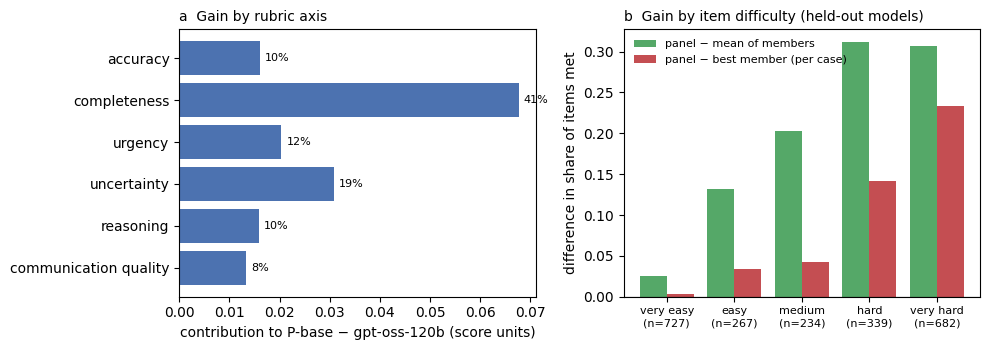

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
dec = axis_dec[axis_dec.vs == 'gpt-oss-120b'].set_index('axis').reindex(AXES)
axs[0].barh([a.replace('_', ' ') for a in AXES], dec.contribution, color='#4C72B0')
for i, (c, s) in enumerate(zip(dec.contribution, dec.share)):
    axs[0].text(c + 0.001, i, f'{s:.0%}', va='center', fontsize=8)
axs[0].invert_yaxis()
axs[0].set_xlabel('contribution to P-base − gpt-oss-120b (score units)')
axs[0].set_title('a  Gain by rubric axis', loc='left', fontsize=10)
x = np.arange(len(diff))
axs[1].bar(x - 0.2, diff.panel_minus_mean, 0.4, label='panel − mean of members', color='#55A868')
axs[1].bar(x + 0.2, diff.panel_minus_best, 0.4, label='panel − best member (per case)', color='#C44E52')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xticks(x)
axs[1].set_xticklabels([f'{s}\n(n={n})' for s, n in zip(diff.stratum, diff['items'])], fontsize=8)
axs[1].set_ylabel('difference in share of items met')
axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title('b  Gain by item difficulty (held-out models)', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_NB03_mechanism.png'), dpi=220)
